In [1]:
from mnesis_boilerplate import torch, pd, sns, plt, data_cache, RECOMPUTE, DEBUG, phi, loss_fn, Params
from mnesis_boilerplate import printfig, pprint
from mnesis_chains import StochasticSpikingPattern, HD_SNN
# RECOMPUTE = True

datetag = '2026-09-07'
Using device: mps


In [2]:
opt_dict = dict(num_epochs=128)
opt = Params(**opt_dict)
opt

Params(datetag='2026-09-07', N_neuron=1024, num_delay=41, N_pattern=16, N_time=1000, N_pretime=50, p_A=0.00016, p_flip=0.01, seed=2026, lif_beta=0.7, lif_threshold=0.75, learn_beta=False, learn_threshold=False, do_pinv=True, do_deconv=True, num_epochs=128, num_warmup_epochs=16, base_lr=0.04, final_lr=0.0004, delta1=0.003, delta2=1e-05, dropout=0.6, alpha_surrogate=5.0, surrogate_name='FastSigmoid', loss_name='SpikeF1scoreLoss', reset_mechanism='zero', optimizer='adadelta', verbose=False, fig_width=17.2, fig_height=8.6, phi=1.61803, N_time_show=1000, N_neuron_show=1024, i_pattern=0, N_scan=14, N_cv=11)

## optimizing learning parameters with optuna

In [3]:
pprint('Optimizing learning parameters with Optuna: running hyperparameter search and analyzing best trials')

Optimizing learning parameters with Optuna: running hyperparameter search and analyzing best trials


In [4]:
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)
import warnings
warnings.filterwarnings("ignore", category=optuna.exceptions.ExperimentalWarning,)
optuna_filename = data_cache / f"{opt.datetag}_optuna.sqlite3"
lock_filename, study = optuna_filename.with_suffix('.lock'), 1
if RECOMPUTE:
    optuna_filename.unlink(missing_ok=True) # FORCING RECOMPUTE
    lock_filename.unlink(missing_ok=True) # FORCING RECOMPUTE
# lock_filename.unlink(missing_ok=True) # FORCING RECOMPUTE
%ls -l {optuna_filename}

-rw-r-----@ 1 laurent  staff  577536 26 sept. 09:39 ../cached_data/2026-09-07_optuna.sqlite3


In [5]:
lock_filename.exists()

False

In [6]:
def objective(trial):
    new_opt = Params(**opt_dict)

    new_opt.do_deconv = trial.suggest_categorical('do_deconv', [True, False])
    new_opt.do_pinv = trial.suggest_categorical('do_pinv', [True, False])
    new_opt.learn_beta = trial.suggest_categorical('learn_beta', [True, False])
    new_opt.learn_threshold = trial.suggest_categorical('learn_threshold', [True, False])
    new_opt.reset_mechanism = trial.suggest_categorical('reset_mechanism', ['zero', 'subtract'])
    new_opt.optimizer = trial.suggest_categorical('optimizer', ['adamw', 'rmsprop', 'adadelta', 'sgd', 'adam']) # 'adagrad', 'sparseadam',

    # new_opt.surrogate_name = trial.suggest_categorical('surrogate_name', ['FastSigmoid', 'LeakySpikeOperator', 'ATan', 'Sigmoid', 'SpikeRateEscape'])
    # new_opt.loss_name = trial.suggest_categorical('loss_name', [  'SpikeF1scoreLoss', 'MSELoss', 'L1Loss'])

    new_opt.lif_beta = trial.suggest_float('lif_beta', 0, 1)
    scale = 10
    scale = 3.618
    new_opt.alpha_surrogate = trial.suggest_float('alpha_surrogate', new_opt.alpha_surrogate / scale, new_opt.alpha_surrogate * scale, log=True)
    new_opt.base_lr = trial.suggest_float('base_lr', new_opt.base_lr / scale, new_opt.base_lr * scale, log=True)
    new_opt.final_lr = trial.suggest_float('final_lr', new_opt.final_lr / scale, new_opt.final_lr * scale, log=True)
    new_opt.delta1 = trial.suggest_float('delta1', new_opt.delta1 / scale, min((new_opt.delta1 * scale, .99)), log=True)
    new_opt.delta2 = trial.suggest_float('delta2', new_opt.delta2 / scale, min((new_opt.delta2 * scale, .99)), log=True)
    new_opt.dropout = trial.suggest_float('dropout', 0, 1)
    new_opt.lif_threshold = trial.suggest_float('lif_threshold', new_opt.lif_threshold / scale, new_opt.lif_threshold * scale, log=True)

    try:
        hd = HD_SNN(new_opt, StochasticSpikingPattern())
        hd.update_weight()
        hd.learn_model(verbose=False)

        with torch.no_grad():
            # draw causes (SMs) - hidden to the observer
            target_ =hd.pattern_object()
            input_spikes = hd.get_input_spikes(target=target_)
            _, _, spikes = hd.forward_pass(input_spikes)
            spikes_ = spikes[:, :, (hd.opt.N_pretime+hd.opt.num_delay):(hd.opt.N_time+hd.opt.N_pretime)]
            loss_val = loss_fn(spikes_, target_[:, :, hd.opt.num_delay:])

        return loss_val.item()
    except Exception as e:
        print(f"Error occurred: {e}")
        return 1.

N_optuna_scan = 100
N_optuna_scan = 16
N_optuna_scan = 1000
N_optuna_scan = 200 // DEBUG**2


if not lock_filename.exists():
    # 3. Create a study object and optimize the objective function.
    study = optuna.create_study(
        storage=f"sqlite:///{str(optuna_filename)}",
        sampler=optuna.samplers.TPESampler(multivariate=True, warn_independent_sampling=False),
        direction="minimize",
        load_if_exists=True,
        study_name=opt.datetag,
    )

    if len(study.trials) < N_optuna_scan:
        print(f"Optuna file not found or unlocked: {optuna_filename}, starting optimization.")
        lock_filename.touch(exist_ok=True)

        if len(study.trials)>0:
            print("So far, Best params: ", study.best_params, end=', ')
            print("Best value: ", study.best_value)

        print(
            f"Starting optimization on {max(N_optuna_scan - len(study.trials), 0)} trials with {len(study.trials)} existing trials."
        )
        study.optimize(objective, n_trials=max((N_optuna_scan - len(study.trials), 0)), n_jobs=1, show_progress_bar=True)
        lock_filename.unlink(missing_ok=True)
else:
    print(f"Optuna file is locked: {lock_filename}, passing.")
    study = None

/var/folders/qt/n82pbkv93fjb7bpt0pj1992w0000gn/T/ipykernel_60776/2570461563.py:53: FutureWarning: `warn_independent_sampling` has been deprecated in v4.9.0. This feature will be removed in v6.0.0. See https://github.com/optuna/optuna/releases/tag/v4.9.0.
  sampler=optuna.samplers.TPESampler(multivariate=True, warn_independent_sampling=False),


In [7]:
if not study is None:
    study = optuna.load_study(storage=f"sqlite:///{str(optuna_filename)}", study_name=opt.datetag)
else:
    print("Study is None (likely due to lock), skipping load.")

In [8]:
if not study is None:
    print(f'number of trials in study: {len(study.trials)}')
else:
    print("Study is None, skipping trials display.")

number of trials in study: 200


In [9]:
if not study is None:
    print(50 * "-.")
    print("Best params: ", study.best_params)
    print("Best value: ", study.best_value)
    # print("Best Trial params: ", study.best_trial.params)
else:
    print("Study is None, skipping best-trial summary.")

-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.
Best params:  {'do_deconv': False, 'do_pinv': True, 'learn_beta': True, 'learn_threshold': False, 'reset_mechanism': 'subtract', 'optimizer': 'adadelta', 'lif_beta': 0.5059045069294882, 'alpha_surrogate': 2.2146785982323722, 'base_lr': 0.01730338679940104, 'final_lr': 0.0010346647150370032, 'delta1': 0.002107247326947176, 'delta2': 4.448331901813866e-06, 'dropout': 0.8058842488879345, 'lif_threshold': 0.6131162111477724}
Best value:  0.08661091327667236


In [10]:
if not study is None: 
    import numpy as np
    print("=" * 60)
    print("OPTUNA STUDY ANALYSIS")
    print("=" * 60)

    # 1. Parameter Importances (Ranking of Most Important Parameters)
    print("\n[1] PARAMETER IMPORTANCE RANKING:")
    try:
        importance_dict = optuna.importance.get_param_importances(study)
        for param, imp in sorted(importance_dict.items(), key=lambda item: item[1], reverse=True):
            print(f"{param:<30}: {imp:.3f}")
    except Exception as e:
        print("Error computing importance:", str(e))

    # 2. Best Value and Confidence Intervals for Each Parameter
    print("\n[2] BEST VALUES WITH CONFIDENCE INTERVALS:")

    if not study.trials:
        print("No trials found.")
    else:
        best_trial = study.best_trial
        print(f"\nBest Objective Value: {best_trial.value:.5f}")

        # Collect all valid trials
        completed_trials = [t for t in study.trials if t.state == optuna.trial.TrialState.COMPLETE]

        if not completed_trials:
            print("No completed trials available.")
        else:
            # Get top 10% performing trials for confidence interval estimation
            top_trials = sorted(completed_trials, key=lambda t: t.value, reverse=True)[:max(1, len(completed_trials) // 10)]

            params_all = {pname: [] for pname in best_trial.params}
            for trial in top_trials:
                for pname in params_all:
                    if pname in trial.params:
                        params_all[pname].append(trial.params[pname])

            print("\nEstimated Confidence Intervals (Top 10% Trials):")
            for pname in best_trial.params:
                vals = params_all.get(pname, [])
                if vals:
                    # Check if values are boolean
                    if isinstance(vals[0], bool):
                        # For boolean parameters, show mode and frequency
                        true_count = sum(1 for v in vals if v)
                        false_count = len(vals) - true_count
                        most_common = True if true_count >= false_count else False
                        print(f"{pname}\t: Best={best_trial.params[pname]},\t "
                            f"Most Common={most_common}, True: {true_count}/{len(vals)} ({100*true_count/len(vals):.1f}%)")
                    else:
                        # For numeric parameters, compute percentiles
                        try:
                            low = np.percentile(vals, 5)
                            high = np.percentile(vals, 95)
                            median = np.median(vals)
                            print(f"{pname}\t: Best={best_trial.params[pname]:3e},\t "
                                f"Median={median:>8.3e}, 90% CI=[{low:>8.3e}, {high:>8.3e}]")
                        except Exception as e:
                            print(f"{pname}\t: Best={best_trial.params[pname]},\t "
                                f"Error computing stats: {str(e)}")
                else:
                    print(f"{pname:<30}: No data")

    print("\n" + "=" * 60)

OPTUNA STUDY ANALYSIS

[1] PARAMETER IMPORTANCE RANKING:
lif_threshold                 : 0.524
optimizer                     : 0.199
do_pinv                       : 0.154
delta1                        : 0.043
final_lr                      : 0.028
lif_beta                      : 0.021
base_lr                       : 0.014
dropout                       : 0.005
learn_threshold               : 0.003
learn_beta                    : 0.003
alpha_surrogate               : 0.002
reset_mechanism               : 0.002
delta2                        : 0.001
do_deconv                     : 0.001

[2] BEST VALUES WITH CONFIDENCE INTERVALS:

Best Objective Value: 0.08661

Estimated Confidence Intervals (Top 10% Trials):
do_deconv	: Best=False,	 Most Common=True, True: 11/19 (57.9%)
do_pinv	: Best=True,	 Most Common=True, True: 15/19 (78.9%)
learn_beta	: Best=True,	 Most Common=True, True: 11/19 (57.9%)
learn_threshold	: Best=False,	 Most Common=False, True: 7/19 (36.8%)
reset_mechanism	: Best=subtract

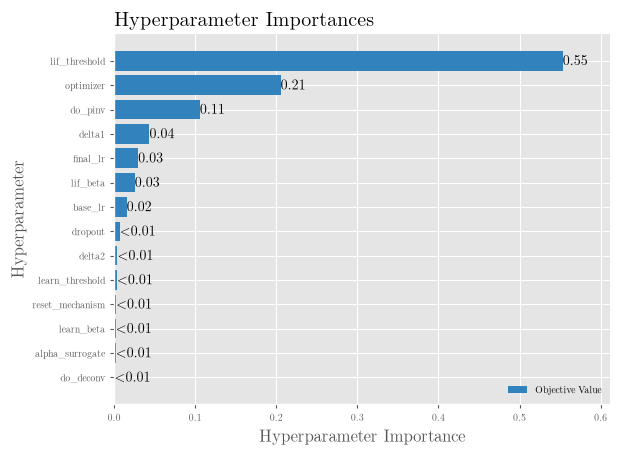

In [11]:
if not study is None:
    import optuna.visualization.matplotlib as vis
    vis.plot_param_importances(study)
else:
    print("Study is None, skipping parameter-importance plot.")

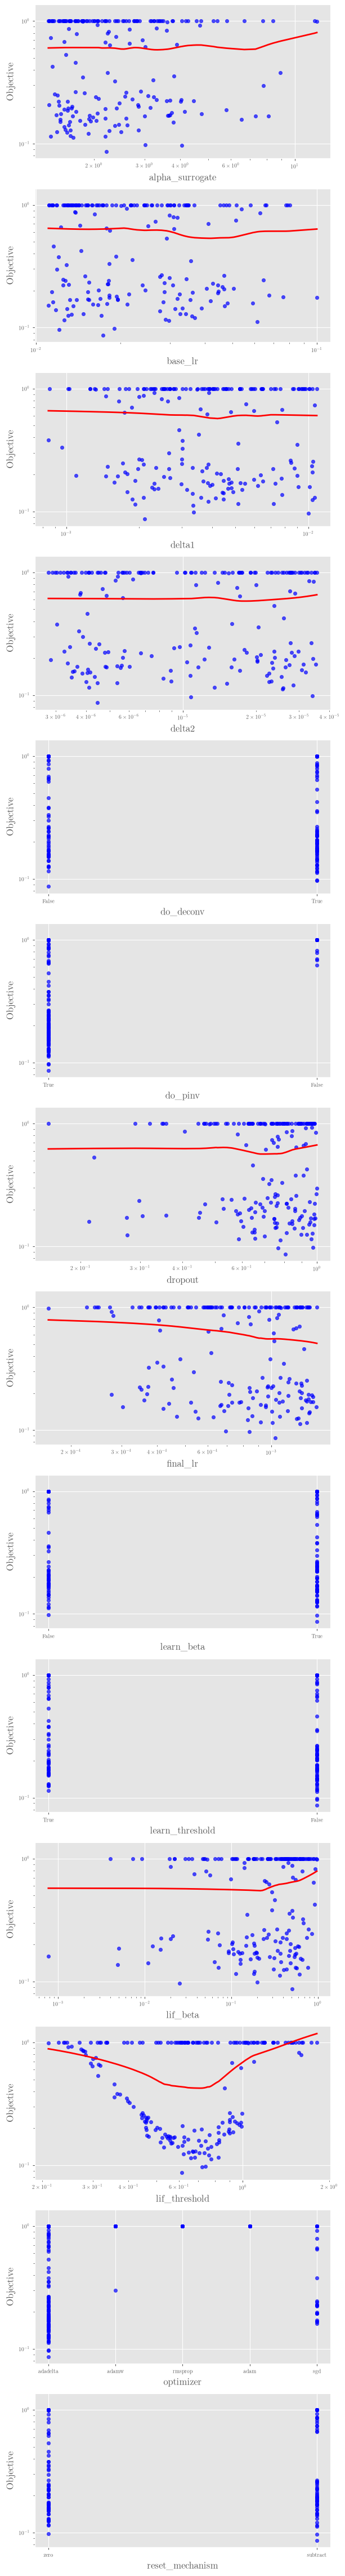

In [12]:
if study is not None:

    params = sorted({k for t in study.trials for k in t.params})
    fig, axes = plt.subplots(len(params), 1, sharey=True)

    # Garantit un itérable même s'il n'y a qu'un seul paramètre
    if len(params) == 1:
        axes = [axes]

    for ax, pname in zip(axes, params):
        xs = [t.params[pname] for t in study.trials if pname in t.params]
        ys = [t.value for t in study.trials if pname in t.params]

        df = pd.DataFrame({"x": xs, "y": ys})

        # Détection explicite du cas binaire (ex: do_deconv, do_pinv)
        unique_vals = set(df["x"].dropna().tolist())
        is_binary = unique_vals.issubset({True, False, 0, 1}) and len(unique_vals) <= 2
        is_numeric = pd.api.types.is_numeric_dtype(df["x"])

        if is_binary:
            df["x"] = df["x"].astype(bool).map({False: "False", True: "True"})
            # ax.scatter(df["x"], df["y"], s=24, alpha=0.8, color="tab:blue", label="Trials")
        elif is_numeric:
            if len(df["x"].unique()) > 1:
                sns.regplot(
                    x="x", y="y", data=df, ax=ax, lowess=True, color="red",
                    line_kws={"lw": 2, "label": "Tendance (LOWESS)"}, scatter=False
                )
            # ax.scatter(df["x"], df["y"], s=20, alpha=0.7, color="blue", label="Trials") TODO propagate to other optuna plots

            # L'échelle log sur x n'est valide que pour des valeurs strictement positives
            if (df["x"] > 0).all():
                ax.set_xscale("log")
        else:
            df["x"] = df["x"].astype(str)
        ax.scatter(df["x"], df["y"], s=20, alpha=0.7, color="blue", label="Trials")

        ax.set_xlabel(pname)
        ax.set_ylabel("Objective")
        ax.set_yscale("log")

    printfig(fig, 'optuna', fig_width=opt.fig_width, fig_height= opt.fig_width / phi * len(params), figpath=None)
    # plt.tight_layout()
else:
    print("Study is None, skipping diagnostic plots.")